# Probabilistic FDM — 非線形楕円型 PDE

PDE: $-\Delta u + u^3 = f$, $(x,y) \in (0,1)^2$, $u=0$ on $\partial(0,1)^2$

prescribed solution: $u^*(x,y) = \sin(\pi x)\sin(\pi y)$

観測モデル: $f = \mathcal{F}(u) + \epsilon$, $\mathcal{F}(u) = D_h u + u^3$ (非線形！)

Laplace 近似:
1. MAP 推定: $\hat{u} = \arg\min [\|u\|^2_{K^{-1}} + \|\mathcal{F}(u) - f\|^2_{\Sigma^{-1}}]$ (Newton 法)
2. 事後分散: $\Sigma^{\text{post}} = K - KJ^\top(JKJ^\top + \Sigma)^{-1}JK$ (Jacobian で線形化)


In [12]:
using Plots
using LinearAlgebra
using SpecialFunctions
using Statistics
using SparseArrays
using Printf
println("Packages loaded.")


Packages loaded.


In [13]:
function matern_kernel_2d(x1, y1, x2, y2; nu=1.5, l=1.0)
    r = sqrt((x1-x2)^2 + (y1-y2)^2)
    r == 0 && return 1.0
    z = sqrt(2*nu) * r / l
    if nu == 0.5; return exp(-z)
    elseif nu == 1.5; return (1 + z) * exp(-z)
    elseif nu == 2.5; return (1 + z + z^2/3) * exp(-z)
    end
end

function kernel_matrix_2d(XY1, XY2; nu=1.5, l=1.0)
    n1, n2 = size(XY1,1), size(XY2,1)
    K = zeros(n1, n2)
    for i in 1:n1, j in 1:n2
        K[i,j] = matern_kernel_2d(XY1[i,1], XY1[i,2], XY2[j,1], XY2[j,2]; nu=nu, l=l)
    end
    return K
end
println("Kernel defined.")


Kernel defined.


In [14]:
# ============================================================
# グリッド設定
# ============================================================
function make_grid(Nx)
    dx = 1.0 / (Nx + 1)
    xs = [dx*i for i in 1:Nx]
    ys = [dx*j for j in 1:Nx]
    xy = hcat([x for y in ys for x in xs], [y for y in ys for x in xs])
    return dx, xy, Nx^2
end

# 解析解 (低周波のみ → FDMで誤差が出やすい)
u_true(x, y)  = sin(pi*x) * sin(pi*y)
neg_lap_u(x,y) = 2*pi^2 * sin(pi*x) * sin(pi*y)
f_rhs(x, y)   = neg_lap_u(x,y) + u_true(x,y)^3

println("Grid and analytical solution defined.")


Grid and analytical solution defined.


In [15]:
# ============================================================
# 情報作用素 D_h = -Delta_h (線形部分, 疎行列)
# ============================================================
function make_Dh_2d(Nx, dx)
    N = Nx^2
    idx(i,j) = (j-1)*Nx + i
    rows, cols, vals = Int[], Int[], Float64[]
    for j in 1:Nx, i in 1:Nx
        k = idx(i,j)
        push!(rows,k); push!(cols,k); push!(vals, 4.0/dx^2)
        i>1   && (push!(rows,k); push!(cols,idx(i-1,j)); push!(vals,-1.0/dx^2))
        i<Nx  && (push!(rows,k); push!(cols,idx(i+1,j)); push!(vals,-1.0/dx^2))
        j>1   && (push!(rows,k); push!(cols,idx(i,j-1)); push!(vals,-1.0/dx^2))
        j<Nx  && (push!(rows,k); push!(cols,idx(i,j+1)); push!(vals,-1.0/dx^2))
    end
    return sparse(rows, cols, vals, N, N)
end

# 非線形情報作用素: F(u) = D_h*u + u^3
function nonlinear_F(u, Dh)
    return Dh*u + u.^3
end

# Jacobian: J(u) = D_h + diag(3*u^2)
function jacobian_F(u, Dh)
    return Matrix(Dh) + Diagonal(3*u.^2)
end

println("Dh and nonlinear operators defined.")


Dh and nonlinear operators defined.


In [16]:
# ============================================================
# 通常の FDM 解 (Newton 法, prior なし)
# ============================================================
function newton_fdm(dx, Nx, f_vals; tol=1e-10, maxiter=100)
    N   = Nx^2
    Dh  = make_Dh_2d(Nx, dx)
    u   = zeros(N)
    for it in 1:maxiter
        F  = nonlinear_F(u, Dh) - f_vals
        J  = jacobian_F(u, Dh)
        du = J \ (-F)
        u .+= du
        if norm(du) < tol
            println("  FDM Newton converged at iter $(it)")
            break
        end
    end
    return u
end

# ============================================================
# MAP 推定 (Newton 法, prior + likelihood)
# arg min [ ||u||^2_{K^{-1}} + ||F(u) - f||^2_{Sigma^{-1}} ]
# Newton 更新: (J^T Sigma^{-1} J + K^{-1}) du = -J^T Sigma^{-1}(F(u)-f) - K^{-1} u
# ============================================================
function newton_map(dx, Nx, f_vals, K; C=1.0, tau=2, tol=1e-10, maxiter=100)
    N         = Nx^2
    Dh        = make_Dh_2d(Nx, dx)
    u         = zeros(N)
    noise_var = C * dx^(2*tau)
    Sigma_inv = (1.0/noise_var) * I
    K_inv     = inv(Matrix(K) + 1e-8*I)

    for it in 1:maxiter
        F_val = nonlinear_F(u, Dh) - f_vals   # residual
        J     = jacobian_F(u, Dh)              # Jacobian
        H     = J' * Sigma_inv * J + K_inv     # Hessian
        g     = J' * Sigma_inv * F_val + K_inv * u  # gradient
        du    = H \ (-g)
        u .+= du
        if norm(du) < tol
            println("  MAP Newton converged at iter $(it)")
            break
        end
    end
    return u
end

println("Newton functions defined.")


Newton functions defined.


In [17]:
# ============================================================
# Laplace 近似 (MAP 点で Jacobian を使って事後分散を計算)
# Sigma^post = K - K J^T (J K J^T + Sigma_noise)^{-1} J K
# ============================================================
function laplace_posterior(u_map, xy, dx, Nx, K;
                            C=1.0, tau=2, nu_ker=1.5)
    N         = Nx^2
    Dh        = make_Dh_2d(Nx, dx)
    J         = jacobian_F(u_map, Dh)   # MAP 点での Jacobian
    noise_var = C * dx^(2*tau)
    Sigma_noise = noise_var * I

    # 観測: y = F(u_map) ではなく，線形化した観測 J * u_map を使う
    y_lin = J * u_map

    JK  = J * K
    M   = Symmetric(JK * J' + Sigma_noise + 1e-10*I)
    L   = cholesky(M).L
    alpha = L' \ (L \ y_lin)

    mu_post  = K * J' * alpha
    V        = L \ JK
    Sig_post = K - V' * V
    std_post = sqrt.(max.(diag(Sig_post), 0.0))

    return mu_post, std_post
end

println("laplace_posterior defined.")


laplace_posterior defined.


In [18]:
# ============================================================
# Marginal likelihood + Grid search
# ============================================================
function log_mll(u_map, xy, dx, Nx, K; C=1.0, tau=2)
    N         = Nx^2
    Dh        = make_Dh_2d(Nx, dx)
    J         = jacobian_F(u_map, Dh)
    noise_var = C * dx^(2*tau)
    Sigma_noise = noise_var * I
    y_lin = J * u_map
    JK  = J * K
    M   = Symmetric(JK * J' + Sigma_noise + 1e-10*I)
    try
        L     = cholesky(M).L
        alpha = L' \ (L \ y_lin)
        return -0.5*dot(y_lin, alpha) - sum(log.(diag(L))) - 0.5*N*log(2*pi)
    catch
        return -Inf
    end
end

function grid_search(u_map, xy, dx, Nx; tau=2, nu_ker=1.5)
    # y = J * u_map のスケールに合わせた grid
    sigma_f_grid = 10.0 .^ range(-3, 1, length=8)
    l_grid       = 10.0 .^ range(-1, 0, length=8)
    C_grid       = 10.0 .^ range(-3, 2, length=8)

    best_lml = -Inf; best_sf = 1.0; best_l = 0.5; best_C = 1.0
    for sf in sigma_f_grid, l in l_grid, C in C_grid
        K   = Symmetric(sf^2 * kernel_matrix_2d(xy, xy; nu=nu_ker, l=l) + 1e-8*I)
        lml = log_mll(u_map, xy, dx, Nx, K; C=C, tau=tau)
        if lml > best_lml
            best_lml = lml; best_sf = sf; best_l = l; best_C = C
        end
    end
    return best_sf, best_l, best_C, best_lml
end

println("Grid search defined.")


Grid search defined.


In [19]:
# ============================================================
# 設定
# ============================================================
Nx     = 8
nu_ker = 1.5
tau_fixed = 2

dx, xy, N = make_grid(Nx)
println("Nx=$(Nx), N=$(N), dx=$(round(dx,digits=4))")

u_star = [u_true(xy[k,1], xy[k,2]) for k in 1:N]
f_vals = [f_rhs(xy[k,1], xy[k,2]) for k in 1:N]

println("max(u_star) = $(round(maximum(abs.(u_star)), digits=4))")
println("max(f_vals) = $(round(maximum(abs.(f_vals)), digits=4))")

# 通常の FDM 解
println("\nRunning FDM Newton...")
u_fdm = newton_fdm(dx, Nx, f_vals)
err_fdm = maximum(abs.(u_fdm - u_star))
println("FDM L∞ error = $(round(err_fdm, digits=6))")
println("Expected O(h^2) = $(round(dx^2, digits=6))")


Nx=8, N=64, dx=0.1111
max(u_star) = 0.9698
max(f_vals) = 20.0562

Running FDM Newton...
  FDM Newton converged at iter 5
FDM L∞ error = 0.00901
Expected O(h^2) = 0.012346


In [20]:
# ============================================================
# Grid search → MAP 推定 → Laplace 近似
# ============================================================

# まず FDM 解を初期点として grid search
println("Running grid search (using u_fdm as initial MAP)...")
best_sf, best_l, best_C, best_lml = grid_search(u_fdm, xy, dx, Nx;
                                                   tau=tau_fixed, nu_ker=nu_ker)
println("Best: sigma_f=$(round(best_sf,digits=4)), l=$(round(best_l,digits=4)), C=$(round(best_C,digits=4)), lml=$(round(best_lml,digits=4))")

# GP prior
K_prior = Symmetric(best_sf^2 * kernel_matrix_2d(xy, xy; nu=nu_ker, l=best_l) + 1e-8*I)

# MAP 推定
println("\nRunning MAP Newton...")
u_map = newton_map(dx, Nx, f_vals, K_prior; C=best_C, tau=tau_fixed)
err_map = maximum(abs.(u_map - u_star))
println("MAP L∞ error = $(round(err_map, digits=6))")

# Laplace 近似
mu_post, std_post = laplace_posterior(u_map, xy, dx, Nx, K_prior;
                                       C=best_C, tau=tau_fixed, nu_ker=nu_ker)
println("max std = $(round(maximum(std_post), digits=6))")
println("FDM err = $(round(err_fdm, digits=6))")


Running grid search (using u_fdm as initial MAP)...
Best: sigma_f=0.1931, l=0.7197, C=0.001, lml=-233.868

Running MAP Newton...
  MAP Newton converged at iter 5
MAP L∞ error = 0.00901
max std = 4.0e-6
FDM err = 0.00901


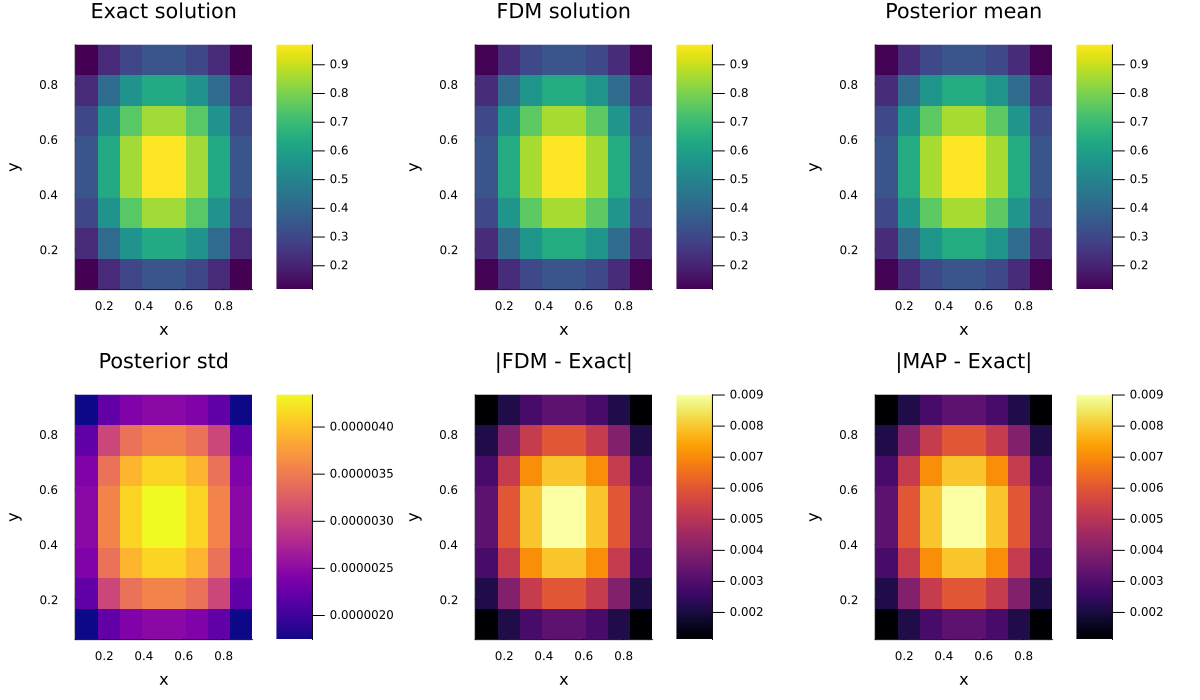

Saved!


In [21]:
# ============================================================
# 可視化
# ============================================================
xs_int = [dx*(i) for i in 1:Nx]
ys_int = [dx*(j) for j in 1:Nx]

function to_grid(u, Nx); reshape(u, Nx, Nx); end

U_star = to_grid(u_star, Nx)
U_fdm  = to_grid(u_fdm,  Nx)
U_map  = to_grid(mu_post, Nx)
U_std  = to_grid(std_post, Nx)
U_err_fdm = to_grid(abs.(u_fdm   - u_star), Nx)
U_err_map = to_grid(abs.(mu_post - u_star), Nx)

clim_u = (minimum(U_star), maximum(U_star))

p1 = heatmap(xs_int, ys_int, U_star';   title="Exact solution",   color=:viridis, clims=clim_u, xlabel="x", ylabel="y")
p2 = heatmap(xs_int, ys_int, U_fdm';    title="FDM solution",     color=:viridis, clims=clim_u, xlabel="x", ylabel="y")
p3 = heatmap(xs_int, ys_int, U_map';    title="Posterior mean",   color=:viridis, clims=clim_u, xlabel="x", ylabel="y")
p4 = heatmap(xs_int, ys_int, U_std';    title="Posterior std",    color=:plasma,  xlabel="x", ylabel="y")
p5 = heatmap(xs_int, ys_int, U_err_fdm'; title="|FDM - Exact|",  color=:inferno, xlabel="x", ylabel="y")
p6 = heatmap(xs_int, ys_int, U_err_map'; title="|MAP - Exact|",  color=:inferno, xlabel="x", ylabel="y")

fig = plot(p1, p2, p3, p4, p5, p6; layout=(2,3), size=(1200,700), margin=5*Plots.mm)
display(fig)
savefig(fig, "nonlinear_elliptic_posterior.png")
println("Saved!")


  FDM Newton converged at iter 5
  MAP Newton converged at iter 5
Nx=4: FDM err=0.02756, MAP err=0.02756, max std=3.0e-5
  FDM Newton converged at iter 5
  MAP Newton converged at iter 5
Nx=6: FDM err=0.01465, MAP err=0.01465, max std=1.0e-5
  FDM Newton converged at iter 5
  MAP Newton converged at iter 5
Nx=8: FDM err=0.00901, MAP err=0.00901, max std=0.0
  FDM Newton converged at iter 5
  MAP Newton converged at iter 5
Nx=12: FDM err=0.00438, MAP err=0.00438, max std=0.0
Saved!


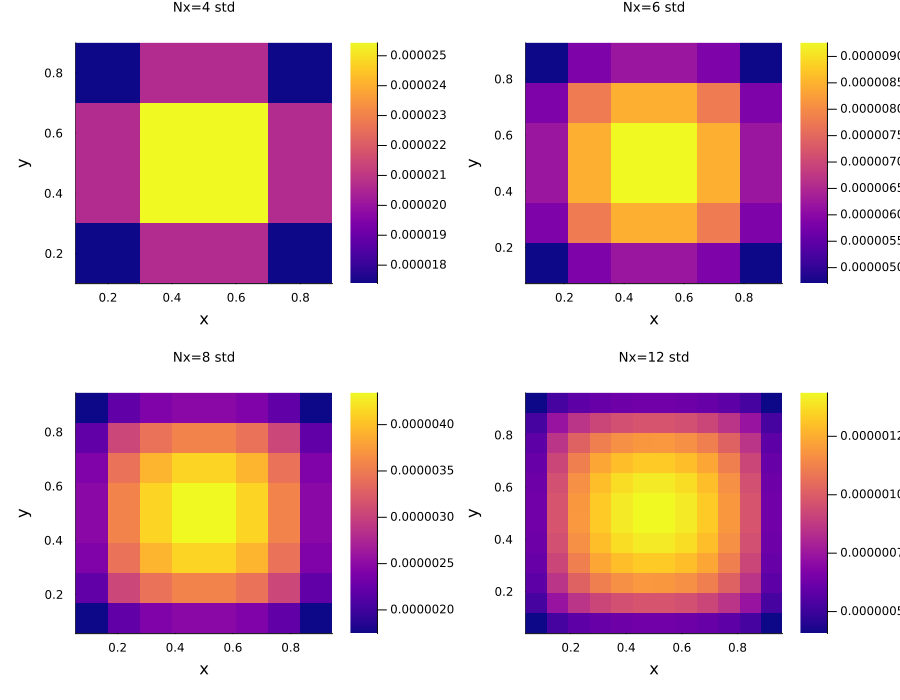

In [22]:
# ============================================================
# Nx sweep
# ============================================================
Nx_list = [4, 6, 8, 12]
plots_sweep = []

for nx in Nx_list
    dxx, xym, Nn = make_grid(nx)
    u_st = [u_true(xym[k,1], xym[k,2]) for k in 1:Nn]
    f_vl = [f_rhs(xym[k,1], xym[k,2]) for k in 1:Nn]

    u_fd = newton_fdm(dxx, nx, f_vl)

    sf, bl, bc, _ = grid_search(u_fd, xym, dxx, nx; tau=tau_fixed, nu_ker=nu_ker)
    Kp = Symmetric(sf^2 * kernel_matrix_2d(xym, xym; nu=nu_ker, l=bl) + 1e-8*I)
    u_m = newton_map(dxx, nx, f_vl, Kp; C=bc, tau=tau_fixed)
    mu_p, std_p = laplace_posterior(u_m, xym, dxx, nx, Kp; C=bc, tau=tau_fixed, nu_ker=nu_ker)

    err_fd  = round(maximum(abs.(u_fd - u_st)), digits=5)
    err_map = round(maximum(abs.(mu_p - u_st)), digits=5)
    println("Nx=$(nx): FDM err=$(err_fd), MAP err=$(err_map), max std=$(round(maximum(std_p),digits=5))")

    xsi = [dxx*(i) for i in 1:nx]
    ysi = [dxx*(j) for j in 1:nx]
    pp = heatmap(xsi, ysi, reshape(std_p, nx, nx)';
                 title="Nx=$(nx) std", xlabel="x", ylabel="y",
                 color=:plasma, titlefontsize=9)
    push!(plots_sweep, pp)
end

fig_sweep = plot(plots_sweep...; layout=(2,2), size=(900,700), margin=5*Plots.mm)
display(fig_sweep)
savefig(fig_sweep, "nonlinear_elliptic_nx_sweep.png")
println("Saved!")
